# 01 · Audit data harga dan klasifikasi gap

**Bab 3 Subbab 3.6.1.** Data harga diperiksa terhadap duplikasi waktu, urutan, nilai hilang, harga nonpositif, dan
konsistensi OHLC. Setiap celah (*gap*) antarbar diklasifikasikan memakai jadwal perdagangan sumber data:

- **penutupan terjadwal** (jeda harian, akhir pekan) → wajar, fitur berlanjut;
- **penutupan sesuai bursa** (libur CME yang terdokumentasi) → wajar, fitur berlanjut;
- **tak terjelaskan** → memutus keadaan indikator; perhitungan dimulai ulang sebagai **segmen** baru.

Label tidak boleh melompati gap jenis apa pun (dibahas di notebook 02).

**Input:** harga XAUUSD H1 MetaQuotes-Demo, jadwal gap beku `configs/phase4-market-gaps.toml`
**Output:** `01_harga.parquet`

In [1]:
import tomllib
from pathlib import Path

# Cari akar repositori (folder yang memuat pyproject.toml) agar notebook bisa dijalankan dari mana saja.
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "pyproject.toml").exists())
CFG = tomllib.loads((ROOT / "configs/phase4-p0.toml").read_text(encoding="utf-8"))
OUT = ROOT / "data/interim/phase4-p0"     # folder hasil; diabaikan Git karena memuat data vendor
OUT.mkdir(parents=True, exist_ok=True)

## 1. Baca data

Satu baris = satu bar H1. Kolom `time` adalah waktu **pembukaan** bar dalam UTC.

In [2]:
import numpy as np
import pandas as pd

harga = pd.read_csv(ROOT / CFG["inputs"]["harga"]["path"])
harga["time"] = pd.to_datetime(harga["time"], utc=True)
harga = harga[["time", "open", "high", "low", "close"]]
print("Jumlah bar :", len(harga))
print("Rentang    :", harga["time"].min(), "s.d.", harga["time"].max())
harga.head()

Jumlah bar : 38799
Rentang    : 2020-01-02 06:00:00+00:00 s.d. 2026-07-31 22:00:00+00:00


,time,open,high,low,close
0,2020-01-02 06:00:00+00:00,1520.26,1520.36,1519.39,1519.39
1,2020-01-02 07:00:00+00:00,1519.37,1520.36,1518.95,1520.19
2,2020-01-02 08:00:00+00:00,1520.20,1520.91,1519.30,1520.87
3,2020-01-02 09:00:00+00:00,1520.94,1521.37,1519.03,1519.11
4,2020-01-02 10:00:00+00:00,1519.11,1520.93,1518.38,1520.75


## 2. Pemeriksaan kualitas dasar

Tidak ada harga yang diisi, diubah, atau diinterpolasi. Bila satu pemeriksaan gagal, notebook berhenti.

In [3]:
ohlc = ["open", "high", "low", "close"]
pemeriksaan = {
    "jumlah bar sesuai arsip beku": len(harga) == CFG["audit"]["expected_rows"],
    "waktu unik": harga["time"].is_unique,
    "waktu berurutan naik": harga["time"].is_monotonic_increasing,
    "waktu tepat di awal jam": (harga["time"].dt.floor("h") == harga["time"]).all(),
    "tidak ada nilai hilang": harga[ohlc].notna().all().all(),
    "harga positif": (harga[ohlc] > 0).all().all(),
    "high >= max(open, close)": (harga["high"] >= harga[["open", "close"]].max(axis=1)).all(),
    "low <= min(open, close)": (harga["low"] <= harga[["open", "close"]].min(axis=1)).all(),
}
hasil = pd.Series(pemeriksaan, name="lulus")
assert hasil.all(), hasil[~hasil]
hasil.to_frame()

,lulus
jumlah bar sesuai arsip beku,True
waktu unik,True
waktu berurutan naik,True
waktu tepat di awal jam,True
tidak ada nilai hilang,True
harga positif,True
"high >= max(open, close)",True
"low <= min(open, close)",True


## 3. Temukan gap

Pada data H1 yang sempurna, bar berikutnya dibuka tepat 1 jam kemudian. Jarak lebih dari 1 jam = gap.

In [4]:
jarak = harga["time"].diff()
posisi_gap = np.flatnonzero(jarak > pd.Timedelta(hours=1))      # indeks bar PERTAMA setelah gap
print("Jumlah gap:", len(posisi_gap), "(arsip beku:", CFG["audit"]["expected_total_gaps"], ")")
assert len(posisi_gap) == CFG["audit"]["expected_total_gaps"]
(jarak.iloc[posisi_gap] / pd.Timedelta(hours=1)).value_counts().rename("jumlah").rename_axis("lama gap (jam)").head(10).to_frame()

Jumlah gap: 1705 (arsip beku: 1705 )


,jumlah
lama gap (jam),
2.0,1231
50.0,279
3.0,84
4.0,29
51.0,28
6.0,13
49.0,11
74.0,10
53.0,7


## 4. Jadwal perdagangan MetaQuotes

Jadwal diturunkan dari arsip harga sebelum model apa pun dijalankan, lalu dibekukan pada 16 September 2026:

- **Rezim sesi**: untuk rentang tanggal tertentu, jam UTC mana saja yang dijadwalkan buka pada hari Senin–Jumat.
  Rezim berganti mengikuti pergeseran *daylight saving time* AS/Eropa.
- **Pengecualian**: libur bursa CME (misalnya Good Friday, Thanksgiving) dengan sumber dokumen resmi CME.

In [5]:
import hashlib

jadwal_path = ROOT / CFG["inputs"]["jadwal_gap"]["path"]
assert hashlib.sha256(jadwal_path.read_bytes()).hexdigest() == CFG["inputs"]["jadwal_gap"]["sha256"]
jadwal = tomllib.loads(jadwal_path.read_text(encoding="utf-8"))["sources"]["metaquotes-demo"]

rezim = pd.DataFrame(jadwal["session_regimes"])[["start", "end", "scheduled_weekdays", "scheduled_hours_utc"]]
rezim["start"] = pd.to_datetime(rezim["start"], utc=True)
rezim["end"] = pd.to_datetime(rezim["end"], utc=True)
rezim["jam_buka"] = rezim["scheduled_hours_utc"].map(lambda j: f"{min(j):02d}:00–{max(j):02d}:00 ({len(j)} jam)")

pengecualian = pd.DataFrame(jadwal["exceptions"])
pengecualian["start"] = pd.to_datetime(pengecualian["start"], utc=True)
pengecualian["end"] = pd.to_datetime(pengecualian["end"], utc=True)

print("Rezim sesi:", len(rezim), "· pengecualian libur:", len(pengecualian))
display(rezim[["start", "end", "jam_buka"]].head(6))
pengecualian[["event", "start", "end", "classification", "evidence_identifier"]].head(6)

Rezim sesi: 27 · pengecualian libur: 69


,start,end,jam_buka
0,2020-01-01 00:00:00+00:00,2020-03-09 00:00:00+00:00,01:00–23:00 (23 jam)
1,2020-03-09 00:00:00+00:00,2020-03-30 00:00:00+00:00,01:00–22:00 (22 jam)
2,2020-03-30 00:00:00+00:00,2020-10-26 00:00:00+00:00,01:00–23:00 (23 jam)
3,2020-10-26 00:00:00+00:00,2020-11-02 00:00:00+00:00,00:00–22:00 (23 jam)
4,2020-11-02 00:00:00+00:00,2021-03-15 00:00:00+00:00,01:00–23:00 (23 jam)
5,2021-03-15 00:00:00+00:00,2021-03-29 00:00:00+00:00,00:00–22:00 (23 jam)


,event,start,end,classification,evidence_identifier
0,Martin Luther King Jr. Day,2020-01-20 20:00:00+00:00,2020-01-21 00:00:00+00:00,exchange_aligned_observed_closure,cme-holiday-2020
1,Presidents Day,2020-02-17 20:00:00+00:00,2020-02-18 00:00:00+00:00,exchange_aligned_observed_closure,cme-holiday-2020
2,Good Friday,2020-04-10 01:00:00+00:00,2020-04-11 00:00:00+00:00,exchange_aligned_observed_closure,cme-holiday-2020
3,Memorial Day,2020-05-25 20:00:00+00:00,2020-05-26 00:00:00+00:00,exchange_aligned_observed_closure,cme-holiday-2020
4,Observed Independence Day,2020-07-03 20:00:00+00:00,2020-07-04 00:00:00+00:00,exchange_aligned_observed_closure,cme-holiday-2020
5,Labor Day,2020-09-07 20:00:00+00:00,2020-09-08 00:00:00+00:00,exchange_aligned_observed_closure,cme-holiday-2020


## 5. Klasifikasi setiap gap

Untuk setiap gap, daftar jam yang hilang diperiksa:

1. Semua jam yang hilang memang **tidak dijadwalkan buka** → `penutupan_terjadwal`.
2. Jam yang dijadwalkan buka semuanya tercakup **satu** pengecualian libur → `penutupan_sesuai_bursa`.
3. Selain itu → `tak_terjelaskan`, dan keadaan indikator direset.

In [6]:
def dijadwalkan_buka(ts):
    r = rezim[(rezim["start"] <= ts) & (ts < rezim["end"])]
    assert len(r) == 1, f"{ts} tidak tercakup tepat satu rezim"
    r = r.iloc[0]
    return ts.dayofweek in r["scheduled_weekdays"] and ts.hour in r["scheduled_hours_utc"]


def klasifikasi_gap(sebelum, sesudah):
    jam_hilang = pd.date_range(sebelum + pd.Timedelta(hours=1), sesudah, freq="h", inclusive="left")
    jam_terjadwal = [t for t in jam_hilang if dijadwalkan_buka(t)]
    if not jam_terjadwal:
        return "penutupan_terjadwal", None
    for e in pengecualian.itertuples():
        if all(e.start <= t < e.end for t in jam_terjadwal):
            jenis = "penutupan_sesuai_bursa" if e.normal_market_closure else "tak_terjelaskan"
            return jenis, e.event
    return "tak_terjelaskan", None


gap = pd.DataFrame({
    "bar_sebelum": harga["time"].iloc[posisi_gap - 1].to_numpy(),
    "bar_sesudah": harga["time"].iloc[posisi_gap].to_numpy(),
    "posisi": posisi_gap,
})
gap["lama_jam"] = (gap["bar_sesudah"] - gap["bar_sebelum"]) / pd.Timedelta(hours=1)
gap[["kelas", "acara"]] = [klasifikasi_gap(a, b) for a, b in zip(gap["bar_sebelum"], gap["bar_sesudah"])]
gap["kelas"].value_counts().to_frame("jumlah gap")

,jumlah gap
kelas,
penutupan_terjadwal,1627
penutupan_sesuai_bursa,69
tak_terjelaskan,9


In [7]:
tak_jelas = gap[gap["kelas"] == "tak_terjelaskan"]
assert len(tak_jelas) == CFG["audit"]["expected_unexplained_gaps"]
tak_jelas[["bar_sebelum", "bar_sesudah", "lama_jam"]].reset_index(drop=True)

,bar_sebelum,bar_sesudah,lama_jam
0,2021-06-15 13:00:00+00:00,2021-06-15 15:00:00+00:00,2.0
1,2021-06-18 16:00:00+00:00,2021-06-18 18:00:00+00:00,2.0
2,2021-09-24 18:00:00+00:00,2021-09-24 21:00:00+00:00,3.0
3,2025-01-07 04:00:00+00:00,2025-01-07 07:00:00+00:00,3.0
4,2025-07-03 03:00:00+00:00,2025-07-03 12:00:00+00:00,9.0
5,2025-07-04 04:00:00+00:00,2025-07-04 10:00:00+00:00,6.0
6,2025-10-23 20:00:00+00:00,2025-10-23 22:00:00+00:00,2.0
7,2026-02-26 21:00:00+00:00,2026-02-27 03:00:00+00:00,6.0
8,2026-03-11 22:00:00+00:00,2026-03-12 00:00:00+00:00,2.0


## 6. Bentuk segmen

Segmen baru dimulai pada bar pertama setelah gap tak terjelaskan. Kolom `setelah_gap` menandai bar pertama setelah
gap **jenis apa pun**; bar sebelumnya tidak boleh memakai bar itu sebagai akhir label.

In [8]:
harga["setelah_gap"] = False
harga.loc[gap["posisi"], "setelah_gap"] = True
harga["reset"] = False
harga.loc[tak_jelas["posisi"], "reset"] = True
harga["segment_id"] = harga["reset"].cumsum()

segmen = harga.groupby("segment_id")["time"].agg(mulai="min", akhir="max", jumlah_bar="count")
assert len(segmen) == CFG["audit"]["expected_segments"]
segmen

,mulai,akhir,jumlah_bar
segment_id,,,
0,2020-01-02 06:00:00+00:00,2021-06-15 13:00:00+00:00,8550
1,2021-06-15 15:00:00+00:00,2021-06-18 16:00:00+00:00,71
2,2021-06-18 18:00:00+00:00,2021-09-24 18:00:00+00:00,1603
3,2021-09-24 21:00:00+00:00,2025-01-07 04:00:00+00:00,19402
4,2025-01-07 07:00:00+00:00,2025-07-03 03:00:00+00:00,2887
5,2025-07-03 12:00:00+00:00,2025-07-04 04:00:00+00:00,16
6,2025-07-04 10:00:00+00:00,2025-10-23 20:00:00+00:00,1822
7,2025-10-23 22:00:00+00:00,2026-02-26 21:00:00+00:00,2015
8,2026-02-27 03:00:00+00:00,2026-03-11 22:00:00+00:00,204


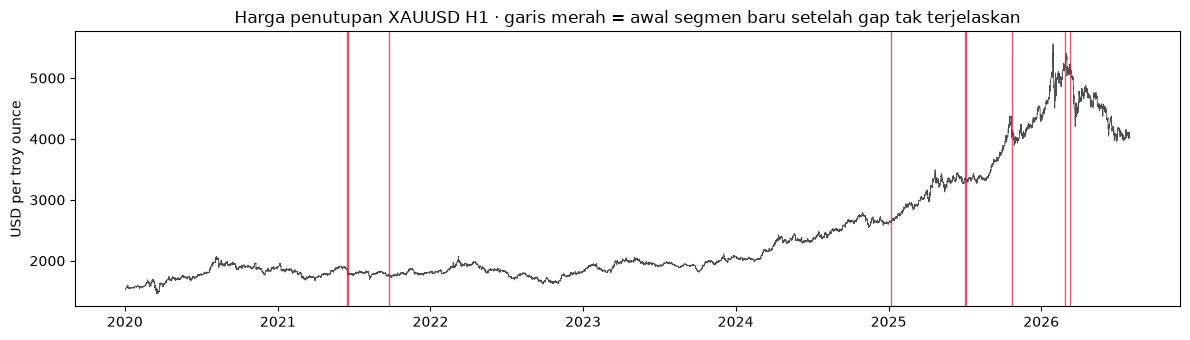

In [9]:
import matplotlib.pyplot as plt

fig, ax = plt.subplots(figsize=(12, 3.5))
ax.plot(harga["time"], harga["close"], lw=0.6, color="0.3")
for t in tak_jelas["bar_sesudah"]:
    ax.axvline(t, color="crimson", lw=1, alpha=0.7)
ax.set_title("Harga penutupan XAUUSD H1 · garis merah = awal segmen baru setelah gap tak terjelaskan")
ax.set_ylabel("USD per troy ounce")
plt.tight_layout()

In [10]:
harga[["time", "open", "high", "low", "close", "setelah_gap", "segment_id"]].to_parquet(OUT / "01_harga.parquet", index=False)
gap.to_csv(OUT / "01_gap.csv", index=False)
print("Tersimpan:", (OUT / "01_harga.parquet").relative_to(ROOT), harga.shape)

Tersimpan: data/interim/phase4-p0/01_harga.parquet (38799, 8)
